In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path


In [8]:
actividad = pd.read_csv(
    "../Data/Procesados/actividad_mensual_ECOBICI.csv",
    dtype={"estacion": "string"}
)

actividad.head()

,mes,estacion,arribos,retiros,movimientos
0,2024-10,001,9070,8787,17857
1,2024-10,002,3734,3543,7277
2,2024-10,003,3746,4056,7802
3,2024-10,004,5040,4761,9801
4,2024-10,005,5354,5454,10808


In [9]:
estaciones = pd.read_csv(
    "../Data/Estaciones_ECOBICI/estaciones_ECOBICI.csv",
    encoding="latin-1",
    dtype={"num_cicloe": "string"}
).dropna(how="all")

estaciones.head()

,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada


In [11]:
actividad_reciente = actividad[
    actividad["mes"].between("2025-10", "2026-09")
]

actividad_estaciones = (
    actividad_reciente
    .groupby("estacion")["movimientos"]
    .sum()
    .div(365)
    .reset_index(name="movimientos_diarios")
)

actividad_estaciones.head()


,estacion,movimientos_diarios
0,001,429.852055
1,002,179.065753
2,003,213.183562
3,004,242.901370
4,005,264.983562


In [12]:
mapa_estaciones = estaciones.merge(
    actividad_estaciones,
    left_on="num_cicloe",
    right_on="estacion",
    how="left"
)

mapa_estaciones.head()


,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus,estacion,movimientos_diarios
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada,423,57.383562
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada,437,48.386301
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada,438,57.460274
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada,439,65.953425
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada,440,124.550685


In [14]:
print("Estaciones:", len(mapa_estaciones))

print(
    "Sin actividad:",
    mapa_estaciones["movimientos_diarios"].isna().sum()
)

mapa_estaciones["movimientos_diarios"].describe()


Estaciones: 677
Sin actividad: 0


count    677.000000
mean     151.166318
std       96.734222
min       16.810959
25%       82.586301
50%      128.019178
75%      193.169863
max      892.219178
Name: movimientos_diarios, dtype: float64

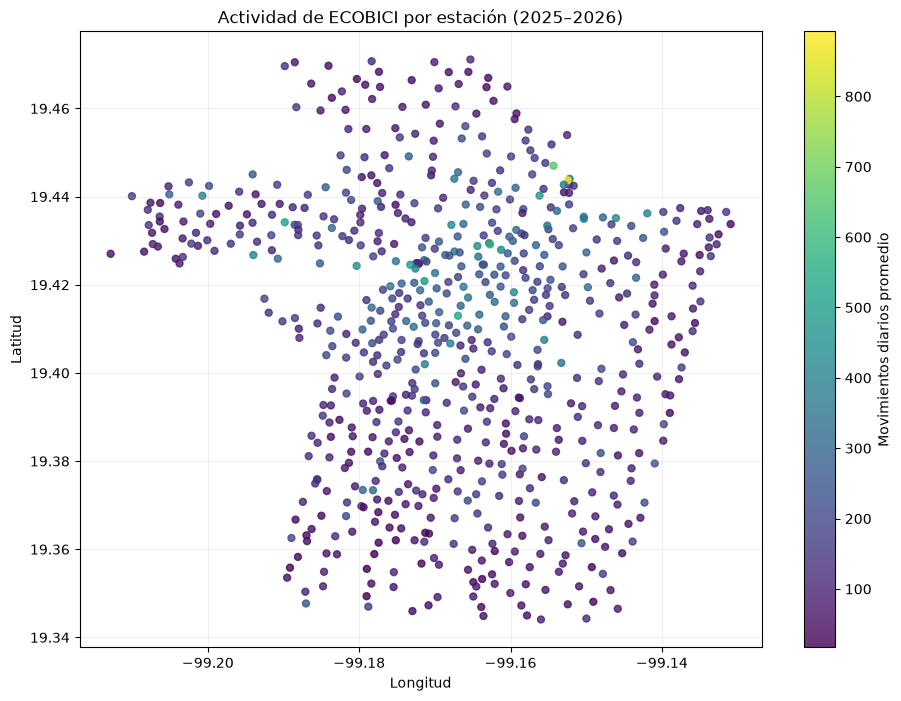

In [16]:
plt.figure(figsize=(11, 8))

plt.scatter(
    mapa_estaciones["longitud"],
    mapa_estaciones["latitud"],
    c=mapa_estaciones["movimientos_diarios"],
    cmap="viridis",
    s=25,
    alpha=0.8
)

plt.colorbar(label="Movimientos diarios promedio")

plt.title("Actividad de ECOBICI por estación (2025–2026)")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(alpha=0.2)

plt.show()


In [17]:
actividad["periodo"] = actividad["mes"].apply(
    lambda x: "2024-2025" if x < "2025-10" else "2025-2026"
)

# Estaciones con registros en los 24 meses
estaciones_completas = (
    actividad.groupby("estacion")["mes"].nunique()
)

estaciones_completas = estaciones_completas[
    estaciones_completas == 24
].index

crecimiento = (
    actividad[actividad["estacion"].isin(estaciones_completas)]
    .groupby(["estacion", "periodo"])["movimientos"]
    .sum()
    .unstack()
)

crecimiento["crecimiento_pct"] = (
    crecimiento["2025-2026"] / crecimiento["2024-2025"] - 1
) * 100

crecimiento = crecimiento.reset_index()

In [18]:
mapa_crecimiento = mapa_estaciones.merge(
    crecimiento[["estacion", "crecimiento_pct"]],
    on="estacion",
    how="left"
)

mapa_crecimiento.head()

,sistema,num_cicloe,calle_prin,calle_secu,colonia,alcaldia,latitud,longitud,sitio_de_e,estatus,estacion,movimientos_diarios,crecimiento_pct
0,Ecobici,423,Moras,Eje 8 Sur Jose Maria Rico,Acacias,Benito Juarez,19.367816,-99.175269,Arroyo,Instalada,423,57.383562,-11.855063
1,Ecobici,437,Moras,Comunal,Acacias,Benito Juarez,19.364916,-99.175985,Arroyo,Instalada,437,48.386301,-19.948327
2,Ecobici,438,Adolfo Prieto,Jose Maria Olloqui,Acacias,Benito Juarez,19.364730,-99.174447,Arroyo,Instalada,438,57.460274,-19.925932
3,Ecobici,439,Amores,Avenida Coyoacan,Acacias,Benito Juarez,19.362037,-99.172683,Arroyo,Instalada,439,65.953425,-9.923293
4,Ecobici,440,Martin Mendalde,M. Lopez Cotilla,Acacias,Benito Juarez,19.361699,-99.171387,Arroyo,Instalada,440,124.550685,-8.341062


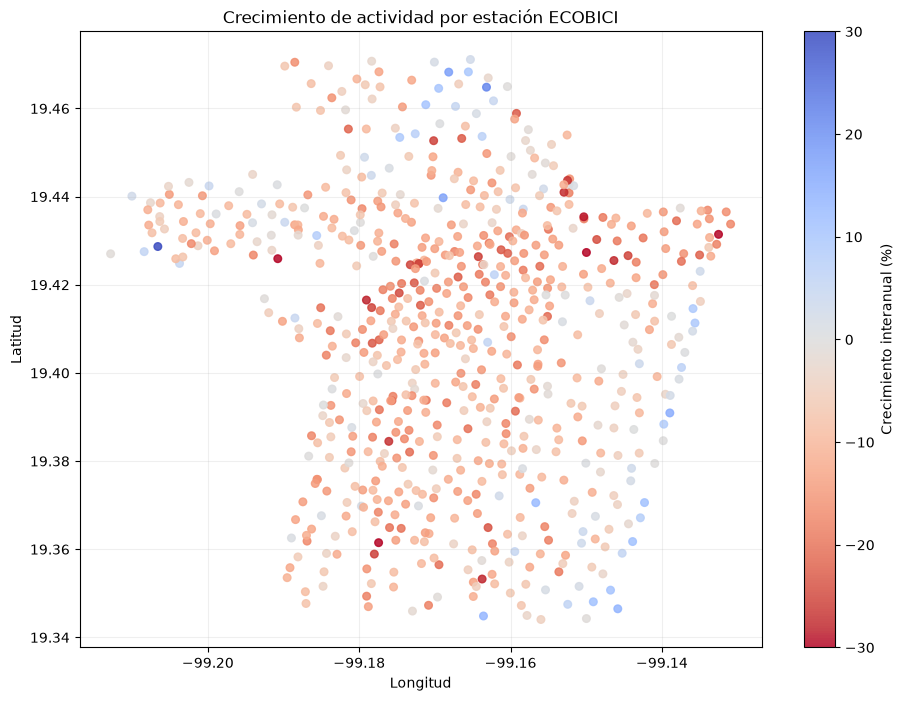

In [19]:

plt.figure(figsize=(11, 8))

plt.scatter(
    mapa_crecimiento["longitud"],
    mapa_crecimiento["latitud"],
    c=mapa_crecimiento["crecimiento_pct"],
    cmap="coolwarm_r",
    vmin=-30,
    vmax=30,
    s=30,
    alpha=0.85
)

plt.colorbar(label="Crecimiento interanual (%)")

plt.title("Crecimiento de actividad por estación ECOBICI")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.grid(alpha=0.2)

plt.show()
